#**Healthcare Data Analysis**

# **Project Domain:- Healthcare Data Analytics| Data Analysis | Business Intelligence**

# **Project Objective:-**


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df1=pd.read_csv('/content/appointments.csv')
#df2=pd.read_csv('/content/billing.csv')
#df3=pd.read_csv('/content/patients.csv')

# **Step 1:- Data Loading & Understanding.**

In [ ]:
df1.head()


,Appointment_ID,Patient_ID,Appointment_Date,Department,Doctor,Appointment_Type,Appointment_Status,Visit_Reason,Wait_Time_Minutes
0,A000001,P04999,2025-04-03,General Medicine,Dr. Neha Kulkarni,Consultation,Completed,Routine Checkup,22.0
1,A000002,P01509,2024-12-28,ENT,Dr. Rahul Verma,Consultation,Completed,Fever,25.0
2,A000003,P03576,2025-07-27,Emergency,Dr. Arjun Reddy,Consultation,Completed,Pregnancy Care,9.0
3,A000004,P02552,2024-05-22,Emergency,Dr. Arjun Reddy,Diagnostic,No Show,Chest Pain,104.0
4,A000005,P01012,2025-08-01,Dermatology,Dr. Isha Patel,Follow-up,Cancelled,Diabetes Follow-up,20.0


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Appointment_ID      25000 non-null  object 
 1   Patient_ID          25000 non-null  object 
 2   Appointment_Date    24125 non-null  object 
 3   Department          24000 non-null  object 
 4   Doctor              23500 non-null  object 
 5   Appointment_Type    23875 non-null  object 
 6   Appointment_Status  24250 non-null  object 
 7   Visit_Reason        23000 non-null  object 
 8   Wait_Time_Minutes   23750 non-null  float64
dtypes: float64(1), object(8)
memory usage: 1.7+ MB


In [ ]:
df1.shape

(25000, 9)

In [ ]:
df1.describe()

,Wait_Time_Minutes
count,23750.000000
mean,54.446611
std,34.594641
min,0.000000
25%,24.000000
50%,48.000000
75%,84.000000
max,120.000000



# **Date and time Formatting.**


In [ ]:
df1['Appointment_Date'] = pd.to_datetime(df1['Appointment_Date'])
df1['Wait_Time_Minutes']= pd.to_timedelta(df1['Wait_Time_Minutes'], unit='m')


In [ ]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype          
---  ------              --------------  -----          
 0   Appointment_ID      25000 non-null  object         
 1   Patient_ID          25000 non-null  object         
 2   Appointment_Date    24125 non-null  datetime64[ns] 
 3   Department          24000 non-null  object         
 4   Doctor              23500 non-null  object         
 5   Appointment_Type    23875 non-null  object         
 6   Appointment_Status  24250 non-null  object         
 7   Visit_Reason        23000 non-null  object         
 8   Wait_Time_Minutes   23750 non-null  timedelta64[ns]
dtypes: datetime64[ns](1), object(7), timedelta64[ns](1)
memory usage: 1.7+ MB


# **Objective :-**
- Understand Data & its type.
- Identify numerical & categorical columns.
- Dectect missing values.
- understand stat's representation.

# **Missing Data Detection**

In [ ]:
df1.isna().sum()

,0
Appointment_ID,0
Patient_ID,0
Appointment_Date,875
Department,1000
Doctor,1500
Appointment_Type,1125
Appointment_Status,750
Visit_Reason,2000
Wait_Time_Minutes,1250


#Missing Data Treatment

In [ ]:
df1['Department'] = df1['Department'].ffill()
df1['Doctor'] = df1['Doctor'].ffill()
df1['Appointment_Status'] = df1['Appointment_Status'].ffill()
df1['Visit_Reason'] = df1['Visit_Reason'].ffill()
df1['Wait_Time_Minutes'] = df1['Wait_Time_Minutes'].fillna(df1['Wait_Time_Minutes'].mean())
df1['Appointment_Type'] = df1['Appointment_Type'].ffill()

In [ ]:
df1.isna().sum()

,0
Appointment_ID,0
Patient_ID,0
Appointment_Date,875
Department,0
Doctor,0
Appointment_Type,0
Appointment_Status,0
Visit_Reason,0
Wait_Time_Minutes,0


In [ ]:
df1.dropna( inplace=True)

In [ ]:
df1.isna().sum()

,0
Appointment_ID,0
Patient_ID,0
Appointment_Date,0
Department,0
Doctor,0
Appointment_Type,0
Appointment_Status,0
Visit_Reason,0
Wait_Time_Minutes,0


# **Step 3: Exploratory Data Analysis (EDA) - Appointments**

# **Q1. What is the average wait time for each department**

Average Wait Time (Minutes) by Department:
Department
General Medicine    56.817468
Cardiology          55.213181
Gynecology          54.639090
Dermatology         54.238469
Pediatrics          54.039137
Emergency           53.597694
Neurology           53.307976
Orthopedics         53.154757
ENT                 52.725078
Name: Wait_Time_Num_Minutes, dtype: float64


/tmp/ipykernel_2036/652662910.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x=avg_wait_time_dept.index, y=avg_wait_time_dept.values, palette='viridis')


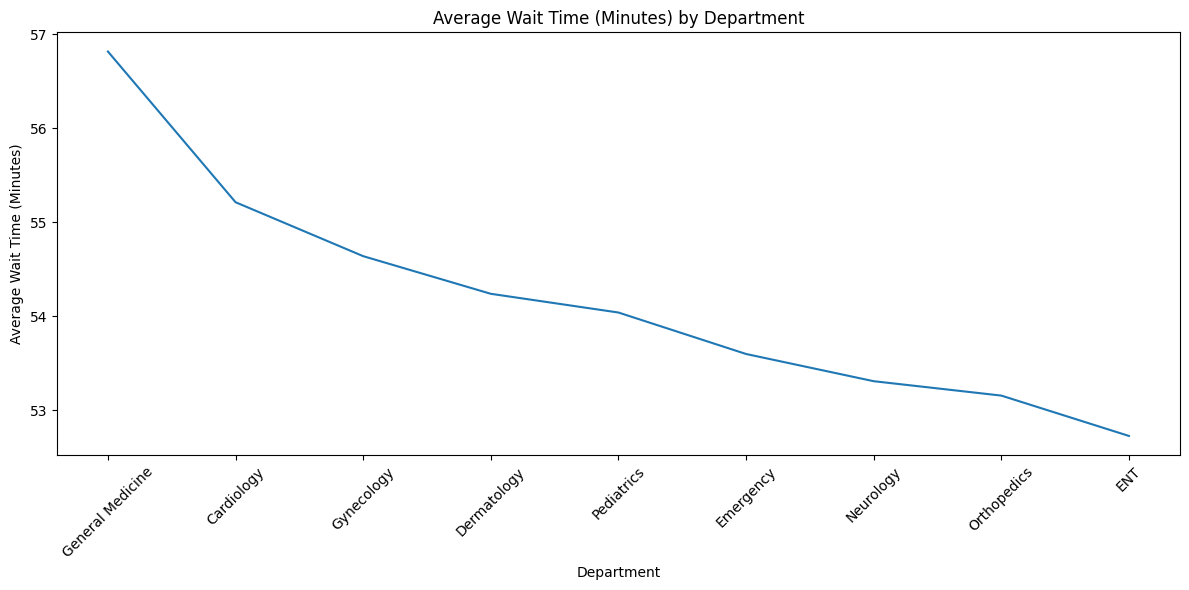

In [ ]:
df1['Wait_Time_Num_Minutes'] = df1['Wait_Time_Minutes'].dt.total_seconds() / 60.0
avg_wait_time_dept = df1.groupby('Department')['Wait_Time_Num_Minutes'].mean().sort_values(ascending=False)
print("Average Wait Time (Minutes) by Department:")
print(avg_wait_time_dept)


plt.figure(figsize=(12, 6))
sns.lineplot(x=avg_wait_time_dept.index, y=avg_wait_time_dept.values, palette='viridis')
plt.title('Average Wait Time (Minutes) by Department')
plt.xlabel('Department')
plt.ylabel('Average Wait Time (Minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Conclusion:**
General medicine department has high average wait time than other department

# **Q2.What percentage of appointments status are completed, cancelled, or missed?**

In [ ]:
df1.head()

,Appointment_ID,Patient_ID,Appointment_Date,Department,Doctor,Appointment_Type,Appointment_Status,Visit_Reason,Wait_Time_Minutes,Wait_Time_Num_Minutes
0,A000001,P04999,2025-04-03,General Medicine,Dr. Neha Kulkarni,Consultation,Completed,Routine Checkup,0 days 00:22:00,22.0
1,A000002,P01509,2024-12-28,ENT,Dr. Rahul Verma,Consultation,Completed,Fever,0 days 00:25:00,25.0
2,A000003,P03576,2025-07-27,Emergency,Dr. Arjun Reddy,Consultation,Completed,Pregnancy Care,0 days 00:09:00,9.0
3,A000004,P02552,2024-05-22,Emergency,Dr. Arjun Reddy,Diagnostic,No Show,Chest Pain,0 days 01:44:00,104.0
4,A000005,P01012,2025-08-01,Dermatology,Dr. Isha Patel,Follow-up,Cancelled,Diabetes Follow-up,0 days 00:20:00,20.0


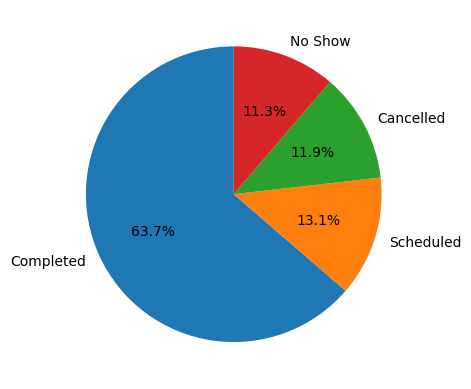

In [ ]:
pie_data = df1['Appointment_Status'].value_counts()
pie_index = pie_data.index
percentage= pie_data.values / pie_data.sum() * 100

plt.pie(pie_data.values, labels=pie_index, autopct='%1.1f%%', startangle=90)
plt.show()

# **Conclusion:**

- Positive performance: Nearly two-thirds of appointments were completed successfully.

# **Q3.Which hospital departments receive the most appointments?**

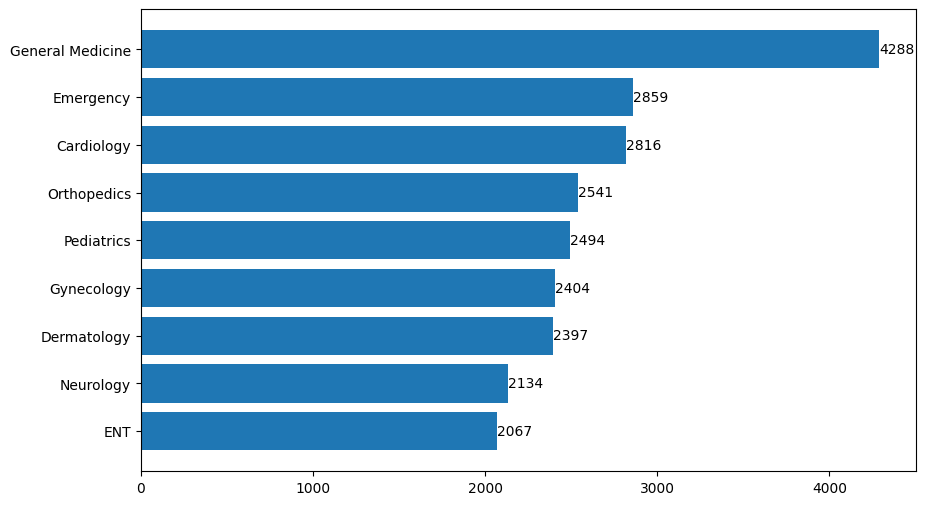

In [ ]:
Hosp_Department = df1['Department'].value_counts().sort_values(ascending=True)
Hosp_Department_index = Hosp_Department.index
plt.figure(figsize=(10, 6))
Hosp_Department_values = Hosp_Department.values
bars= plt.barh(Hosp_Department_index, Hosp_Department_values)
plt.bar_label(bars)
plt.show()

# **Conclusion:**
- Highest demand: General Medicine has the most appointments, with 4,288, so the hospital may need to prioritize staffing and resources in this department.

# **Q4.Which days of the week have the most appointments?**

In [ ]:
df1.head()

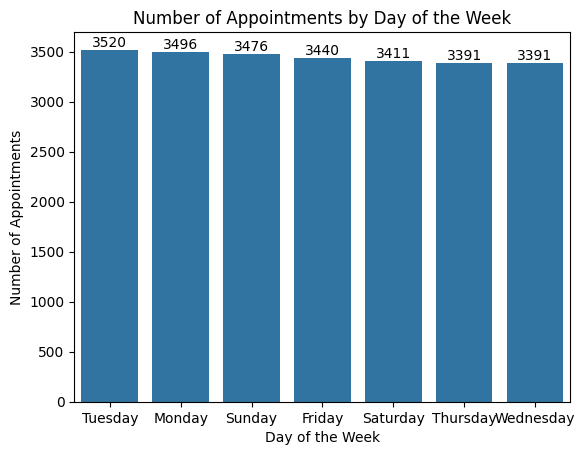

In [ ]:
sns.barplot(x=df1['Appointment_Date'].dt.day_name().value_counts().index,
            y=df1['Appointment_Date'].dt.day_name().value_counts().values)
plt.bar_label(plt.gca().containers[0])
plt.xlabel('Day of the Week')
plt.ylabel('Number of Appointments')
plt.title('Number of Appointments by Day of the Week')
plt.show()
# how to sort days

# **Conclusion:**
- Peak day: Tuesday has the highest demand, so the hospital could review staffing and doctor availability for that day.

#	**Q.5 Which departments have the highest cancellation rates?**

Department
General Medicine    509
Cardiology          323
Emergency           320
Orthopedics         310
Gynecology          302
Pediatrics          285
Dermatology         259
ENT                 243
Neurology           242
Name: count, dtype: int64


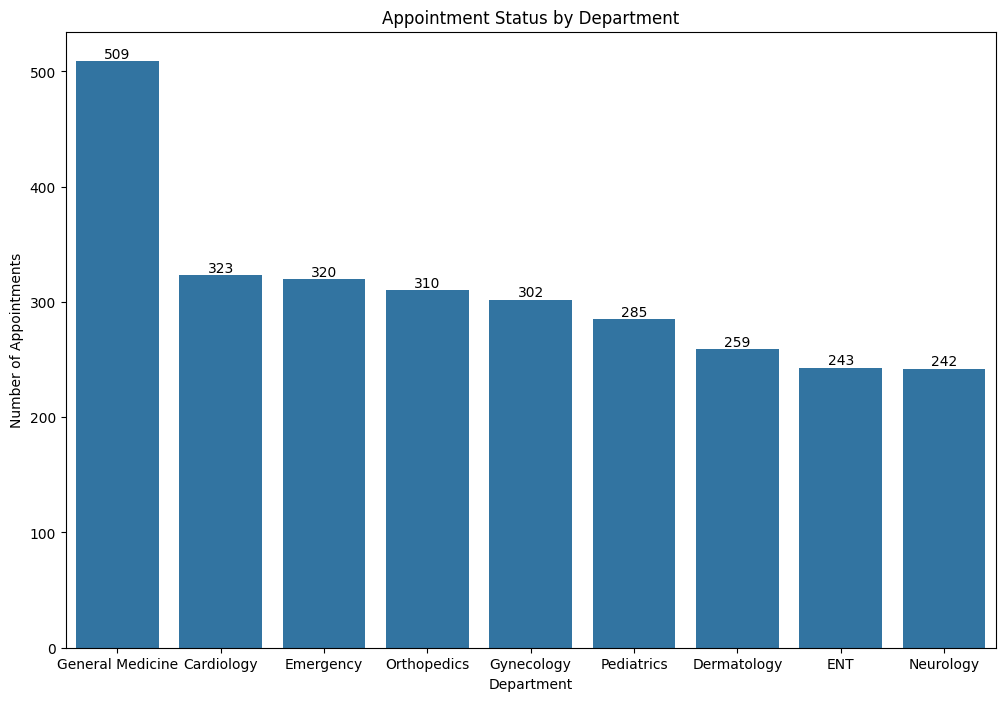

In [ ]:
#cancellation = df1['Appointment_Status' =='cancelled'].groupby('Department').sum()
Appoinment_Summary  = df1.groupby('Appointment_Status')['Department'].value_counts()
Appoinment_Summary = Appoinment_Summary.loc['Cancelled']
print(Appoinment_Summary)
plt.figure(figsize=(12, 8))
sns.barplot(x=Appoinment_Summary.index, y=Appoinment_Summary.values)
plt.bar_label(plt.gca().containers[0])
plt.xlabel('Department')
plt.ylabel('Number of Appointments')
plt.title('Appointment Status by Department')
plt.show()

# how to get particular result(cancelled values) from output of groupby()


##**Conclusion:**
- Geaneral medicine has high rate of cancellation the appoinment due to high waiting time.

In [ ]:
summary = df1.groupby('Appointment_Status')['Department'].value_counts()
#print(summary['Appointment_Status'=='Cancelled'])
print(summary)
print(summary.loc['Cancelled'])

Appointment_Status  Department      
Cancelled           General Medicine     509
                    Cardiology           323
                    Emergency            320
                    Orthopedics          310
                    Gynecology           302
                    Pediatrics           285
                    Dermatology          259
                    ENT                  243
                    Neurology            242
Completed           General Medicine    2618
                    Emergency           1808
                    Cardiology          1745
                    Pediatrics          1540
                    Orthopedics         1533
                    Dermatology         1498
                    Gynecology          1426
                    Neurology           1320
                    ENT                 1296
No Show             General Medicine     437
                    Cardiology           319
                    Emergency            301
                  

# **Billing Analysis**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df2=pd.read_csv('/content/billing.csv')

# **DATA Understanding**

In [ ]:
df2.head()

,Billing_ID,Appointment_ID,Patient_ID,Billing_Date,Department,Insurance_Provider,Payment_Method,Payment_Status,Gross_Amount,Insurance_Coverage,Patient_Paid,Outstanding_Amount
0,B000001,A007952,P00230,2025-01-06,Dermatology,Niva Bupa,UPI,Paid,3253.31,0.00,3253.31,0.00
1,B000002,A017403,P00572,2025-12-20,Gynecology,Niva Bupa,UPI,Paid,5183.72,0.00,NaN,0.00
2,B000003,A004166,P04971,2024-04-15,Pediatrics,Bajaj Allianz,Insurance,Paid,2466.45,1439.63,1026.82,0.00
3,B000004,A014147,P00959,2024-03-14,Orthopedics,Self Pay,Cash,Pending,6118.20,0.00,6118.20,3637.86
4,B000005,A016379,P00009,2025-03-09,Dermatology,Care Health,Insurance,Paid,1520.91,700.32,820.59,0.00


In [ ]:
df2.shape

(18500, 12)

In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18500 entries, 0 to 18499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Billing_ID          18500 non-null  object 
 1   Appointment_ID      18500 non-null  object 
 2   Patient_ID          18500 non-null  object 
 3   Billing_Date        17852 non-null  object 
 4   Department          17760 non-null  object 
 5   Insurance_Provider  17390 non-null  object 
 6   Payment_Method      17575 non-null  object 
 7   Payment_Status      17852 non-null  object 
 8   Gross_Amount        17760 non-null  float64
 9   Insurance_Coverage  17390 non-null  float64
 10  Patient_Paid        17760 non-null  float64
 11  Outstanding_Amount  17668 non-null  float64
dtypes: float64(4), object(8)
memory usage: 1.7+ MB


In [ ]:
df2['Billing_Date'] = pd.to_datetime(df2['Billing_Date'])

In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18500 entries, 0 to 18499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Billing_ID          18500 non-null  object        
 1   Appointment_ID      18500 non-null  object        
 2   Patient_ID          18500 non-null  object        
 3   Billing_Date        17852 non-null  datetime64[ns]
 4   Department          17760 non-null  object        
 5   Insurance_Provider  17390 non-null  object        
 6   Payment_Method      17575 non-null  object        
 7   Payment_Status      17852 non-null  object        
 8   Gross_Amount        17760 non-null  float64       
 9   Insurance_Coverage  17390 non-null  float64       
 10  Patient_Paid        17760 non-null  float64       
 11  Outstanding_Amount  17668 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 1.7+ MB


In [ ]:
df2.describe()

,Billing_Date,Gross_Amount,Insurance_Coverage,Patient_Paid,Outstanding_Amount
count,17852,17760.000000,17390.000000,17760.000000,17668.000000
mean,2025-04-07 23:15:52.632758016,4025.233374,805.392570,3081.804457,578.312857
min,2024-01-01 00:00:00,305.800000,0.000000,0.000000,0.000000
25%,2024-08-13 00:00:00,2125.277500,0.000000,1446.655000,0.000000
50%,2025-03-25 00:00:00,3283.270000,0.000000,2392.795000,0.000000
75%,2025-11-04 00:00:00,5437.157500,1174.692500,4490.355000,568.910000
max,2026-11-02 00:00:00,28722.060000,22011.080000,20098.020000,15880.740000
std,NaN,2468.244687,1549.694143,2302.921197,1287.707039


# **Missing Data Treatment**

In [ ]:
df2.isna().sum()

,0
Billing_ID,0
Appointment_ID,0
Patient_ID,0
Billing_Date,648
Department,740
Insurance_Provider,1110
Payment_Method,925
Payment_Status,648
Gross_Amount,740
Insurance_Coverage,1110


# **Missing DATA handling**

In [ ]:
df2['Billing_Date']= df2['Billing_Date'].ffill ()
df2['Department']= df2['Department'].ffill ()
df2['Insurance_Provider']= df2['Insurance_Provider'].ffill ()
df2['Payment_Status']= df2['Payment_Status'].ffill ()
df2['Payment_Method']= df2['Payment_Method'].ffill ()
df2['Gross_Amount'] = df2['Gross_Amount'].fillna(df2['Gross_Amount'].mean())
df2['Outstanding_Amount'] = df2['Outstanding_Amount'].fillna(df2['Outstanding_Amount'].mean())
df2['Insurance_Coverage'] = df2['Insurance_Coverage'].fillna('Self_Paid')

df2['Patient_Paid'] = df2['Patient_Paid'].fillna(df2['Gross_Amount'] - df2['Outstanding_Amount'])


In [ ]:
df2.isna().sum()

,0
Billing_ID,0
Appointment_ID,0
Patient_ID,0
Billing_Date,0
Department,0
Insurance_Provider,0
Payment_Method,0
Payment_Status,0
Gross_Amount,0
Insurance_Coverage,0


In [ ]:
df2.describe()

,Billing_Date,Gross_Amount,Patient_Paid,Outstanding_Amount
count,18500,18500.000000,18500.000000,18500.000000
mean,2025-04-08 04:04:15.308108032,4025.233374,3092.014472,578.312857
min,2024-01-01 00:00:00,305.800000,-3458.436626,0.000000
25%,2024-08-13 00:00:00,2163.237500,1455.757500,0.000000
50%,2025-03-25 12:00:00,3430.600000,2405.120000,0.000000
75%,2025-11-04 00:00:00,5344.405000,4496.062500,578.312857
max,2026-11-02 00:00:00,28722.060000,20098.020000,15880.740000
std,NaN,2418.373294,2299.395108,1258.416338


# **Exploratory Data Analysis (EDA) - Billings**

# **Q1: Which hospital departments generate the highest billing revenue?**

Department
ENT                 4.572155e+06
Pediatrics          4.708013e+06
Dermatology         5.503622e+06
Gynecology          7.487497e+06
General Medicine    8.105907e+06
Neurology           8.453076e+06
Orthopedics         8.821947e+06
Cardiology          1.246680e+07
Emergency           1.434780e+07
Name: Gross_Amount, dtype: float64


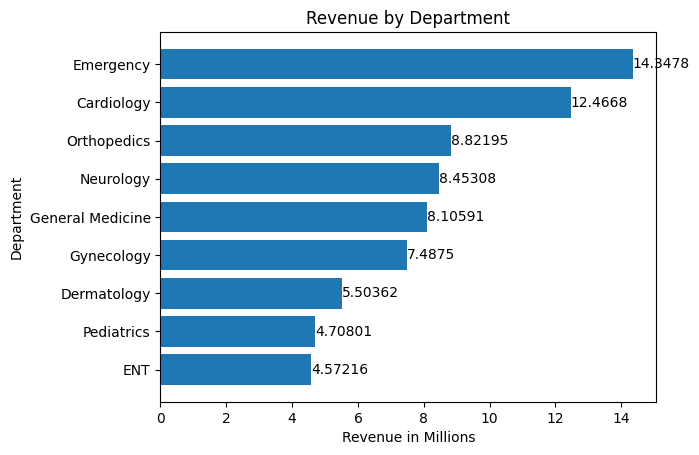

In [ ]:
revenue = df2.groupby('Department')['Gross_Amount'].sum()
revenue = revenue.sort_values(ascending=True)
revenue_index = revenue.index
revenue_values = revenue.values/1000000

print(revenue)
plt.barh(revenue_index, revenue_values)
plt.bar_label(plt.gca().containers[0])
plt.title('Revenue by Department')
plt.xlabel('Revenue in Millions')
plt.ylabel('Department')

plt.show()

# **Conclusion:**
- Highest revenue contributor: Emergency generates approximately ₹14.35 million, making it the leading department by gross billing revenue.

# **Q2: What is the payment status distribution?**

In [ ]:
df2.head()

,Billing_ID,Appointment_ID,Patient_ID,Billing_Date,Department,Insurance_Provider,Payment_Method,Payment_Status,Gross_Amount,Insurance_Coverage,Patient_Paid,Outstanding_Amount
0,B000001,A007952,P00230,2025-01-06,Dermatology,Niva Bupa,UPI,Paid,3253.31,0.0,3253.31,0.00
1,B000002,A017403,P00572,2025-12-20,Gynecology,Niva Bupa,UPI,Paid,5183.72,0.0,5183.72,0.00
2,B000003,A004166,P04971,2024-04-15,Pediatrics,Bajaj Allianz,Insurance,Paid,2466.45,1439.63,1026.82,0.00
3,B000004,A014147,P00959,2024-03-14,Orthopedics,Self Pay,Cash,Pending,6118.20,0.0,6118.20,3637.86
4,B000005,A016379,P00009,2025-03-09,Dermatology,Care Health,Insurance,Paid,1520.91,700.32,820.59,0.00


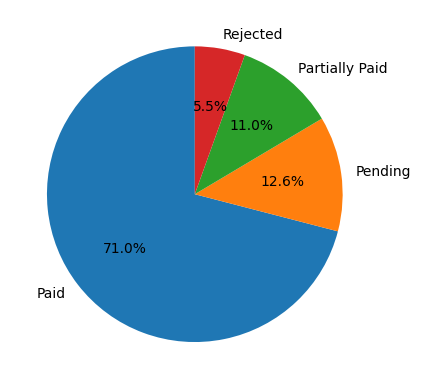

In [ ]:
status = df2['Payment_Status'].value_counts()
total_Count = df2['Payment_Status'].count()
Percentage_Status = status.values / total_Count * 100
plt.pie(Percentage_Status,labels= status.index ,autopct='%1.1f%%', startangle=90)
plt.show()

# **Conclusion:**
- Positive payment performance: 71% of billing records are marked as paid.

# **Q3: Which insurance providers cover the highest amounts?**

In [ ]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18500 entries, 0 to 18499
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Billing_ID          18500 non-null  object        
 1   Appointment_ID      18500 non-null  object        
 2   Patient_ID          18500 non-null  object        
 3   Billing_Date        18500 non-null  datetime64[ns]
 4   Department          18500 non-null  object        
 5   Insurance_Provider  18500 non-null  object        
 6   Payment_Method      18500 non-null  object        
 7   Payment_Status      18500 non-null  object        
 8   Gross_Amount        18500 non-null  float64       
 9   Insurance_Coverage  18500 non-null  object        
 10  Patient_Paid        18500 non-null  float64       
 11  Outstanding_Amount  18500 non-null  float64       
dtypes: datetime64[ns](1), float64(3), object(8)
memory usage: 1.7+ MB


Insurance_Provider
Self Pay         1142470.91
HDFC ERGO        2044322.60
Niva Bupa        2069841.48
ICICI Lombard    2074946.90
Care Health      2177746.07
Star Health      2237043.21
Bajaj Allianz    2259405.63
Name: Insurance_Coverage, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

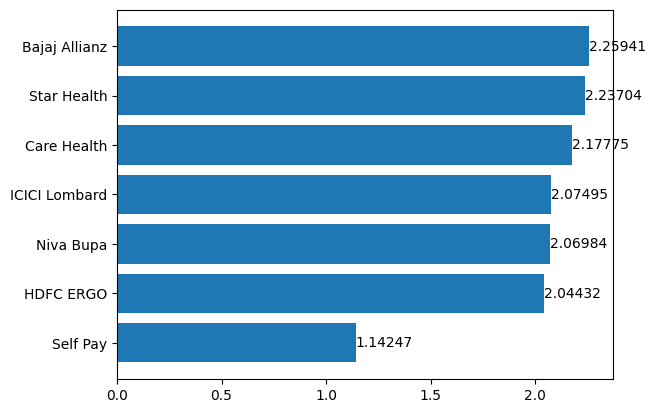

In [ ]:
df2['Insurance_Coverage'] = pd.to_numeric(df2['Insurance_Coverage'], errors='coerce')
Insurance= df2.groupby('Insurance_Provider')['Insurance_Coverage'].sum().sort_values(ascending=True)
print(Insurance)

Insurance = Insurance/1000000

plt.barh(Insurance.index,Insurance.values)
plt.bar_label(plt.gca().containers[0])
plt.show

# **Conclusion:**
- Highest insurance coverage: Bajaj Allianz leads with approximately ₹2.26 million in total coverage.
- Business opportunity: The hospital could review its relationships with insurance providers and investigate claim approval rates, processing times, and rejected claims.

# **Q4: How does hospital billing revenue change over time?**

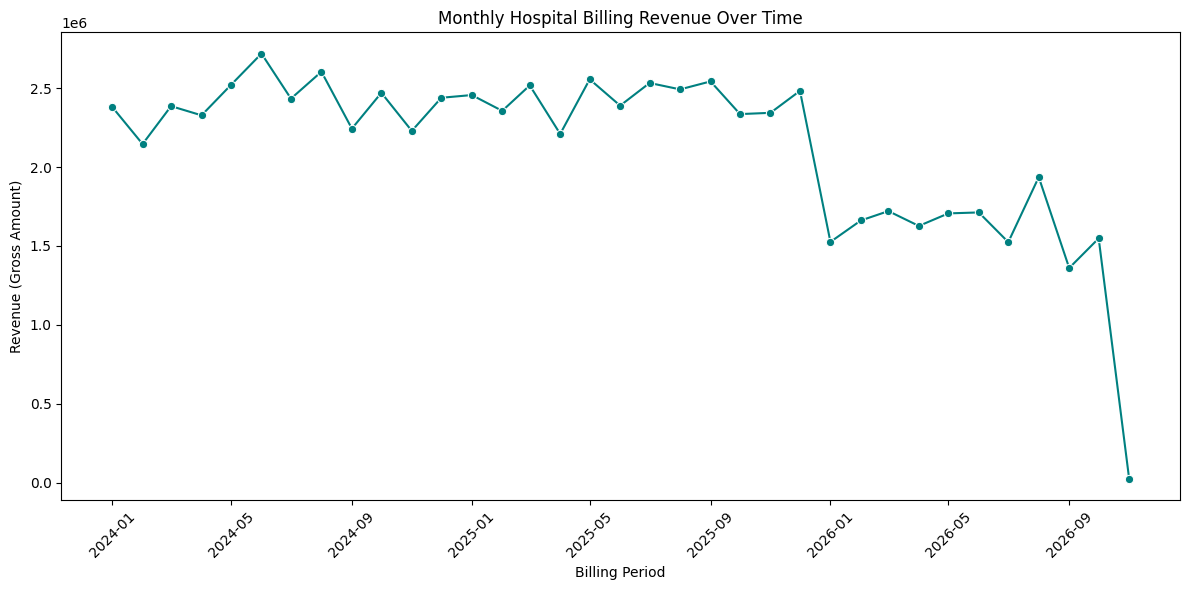

In [ ]:
# Extract Year-Month for proper chronological sorting
df2['Year_Month'] = df2['Billing_Date'].dt.to_period('M')
month_revenue = df2.groupby('Year_Month')['Gross_Amount'].sum()

# Convert the index back to datetime/timestamp for plotting
x_values = month_revenue.index.to_timestamp()
y_values = month_revenue.values

plt.figure(figsize=(12, 6))
sns.lineplot(x=x_values, y=y_values, marker='o', color='teal')
plt.title('Monthly Hospital Billing Revenue Over Time')
plt.xlabel('Billing Period')
plt.ylabel('Revenue (Gross Amount)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Conclusion:**
- hospital billing revenue was relatively stable throughout 2024 and most of 2025, but declined considerably from late 2025 into 2026.

# **Q5: Which departments have the highest outstanding amounts?**

Department
ENT                  6.675243
Pediatrics           6.918061
Dermatology          8.599579
Gynecology           9.812098
General Medicine    11.305213
Neurology           12.482093
Orthopedics         13.044582
Cardiology          17.183993
Emergency           20.967016
Name: Outstanding_Amount, dtype: float64


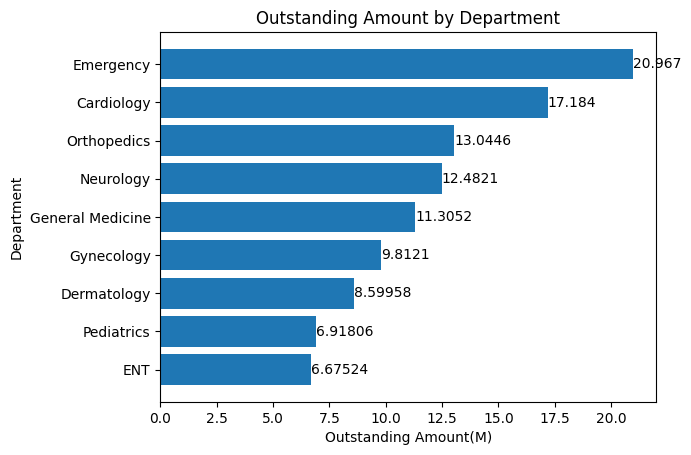

In [ ]:
Dept_outstanding = df2.groupby('Department')['Outstanding_Amount'].sum().sort_values(ascending=True)/100000
print(Dept_outstanding)

plt.barh(Dept_outstanding.index, Dept_outstanding.values)
plt.bar_label(plt.gca().containers[0])
plt.xlabel('Outstanding Amount(M)')
plt.ylabel('Department')
plt.title('Outstanding Amount by Department')
plt.show()


# **Conclusion:**
- Emergency has the highest outstanding amount at approximately ₹20.97 million, followed by Cardiology at ₹17.18 million and Orthopedics at ₹13.04 million. ENT has the lowest outstanding amount at ₹6.68 million.